# Missing values

Rubric:

- categorical and ordinal features: missing values are their own category
- continuous features: no mean or median imputation; use multivariate imputation, the reduced-features model, or a model that handles missing values (XGBoost)
- preprocessing is fit on the training data only
- loop over random states to see how much the imputation randomness changes the results

What we do:

- continuous features: missing values (`NA` or `Exempt` in the raw data) are blank cells in the split files and become NaN. LR, RF and KNN fill them with `IterativeImputer`; XGBoost uses NaN directly.
- categorical and ordinal features: `NA`, `Exempt` and `1111` are each kept as their own category (only `NA` counts as missing).
- the imputer is part of each model's pipeline, so it is fit only on the training part of each CV fold. Its random state changes with the model's random state.

The functions are in `missing_value_tools.py`. The missing-value counts use the training data (2018-2023).

In [1]:
import numpy as np
from matplotlib import pylab as plt

import missing_value_tools as mv

## Data

The split files are made by `data/Data_Process_1.py`. In the continuous features, it turns `NA` and `Exempt` into blank cells.

Read them with `mv.read_split`. It keeps the codes as text in the categorical and ordinal features, and turns blank cells in the continuous features into NaN. A plain `pd.read_csv` turns `NA` into NaN in the categorical and ordinal features, so `NA` would no longer be its own category.

In [2]:
train = mv.read_split('../data/hmda_train.csv')
print(train.shape)
print('denial rate:', round(train['denied'].mean(), 4))

(93103, 28)
denial rate: 0.0946


## 1. Which values are missing

HMDA uses two codes for missing values:

- `NA`: not applicable, for example the lender did not use this value
- `Exempt`: the lender does not have to report this value

Counts in the training data. In the split files, `NA` and `Exempt` in the continuous features are both blank cells; for these four features, the counts by code come from the raw HMDA files.

| Feature | Type | `NA` | `Exempt` |
|---|---|---:|---:|
| `income` | Continuous | 2,519 | 0 |
| `loan_to_value_ratio` | Continuous | 2,727 | 848 |
| `property_value` | Continuous | 1,090 | 864 |
| `loan_term` | Continuous | 219 | 847 |
| `debt_to_income_ratio` | Ordinal | 2,668 | 848 |
| `county_code` | Categorical | 169 | 0 |
| `conforming_loan_limit` | Categorical | 790 | 0 |

- continuous features: `NA` and `Exempt` are both missing values (blank cells in the split files). A numeric column cannot hold a category, so both are imputed.
- debt_to_income_ratio: `NA` is a missing value and is kept as its own category. `Exempt` is kept as another category (Section 3).
- county_code, conforming_loan_limit: `NA` is a missing value and is kept as its own category.

Not missing, kept as normal categories: `Exempt` in debt_to_income_ratio; `1111` (Exempt) in eight categorical features (open-end, business purpose, interest-only, balloon, submission, aus-1, both credit score types); aus-1 `6` (no automated underwriting); credit score type `9` (no credit score used); co-applicant credit score type `10` (no co-applicant).

## 2. How much is missing

For the seven features with missing values: how many rows are missing, and the denial rate with and without the value.

In [3]:
audit = mv.missing_audit(train)
print(audit.to_string())
audit.to_csv('../results/missing_audit.csv', index=False)

                 feature         type  missing_count  missing_percent  denial_rate_missing  denial_rate_not_missing
0                 income   continuous           2519             2.71                0.100                    0.094
1    loan_to_value_ratio   continuous           3575             3.84                0.298                    0.087
2         property_value   continuous           1954             2.10                0.501                    0.086
3              loan_term   continuous           1066             1.14                0.154                    0.094
4   debt_to_income_ratio      ordinal           2668             2.87                0.270                    0.089
5            county_code  categorical            169             0.18                0.414                    0.094
6  conforming_loan_limit  categorical            790             0.85                0.065                    0.095


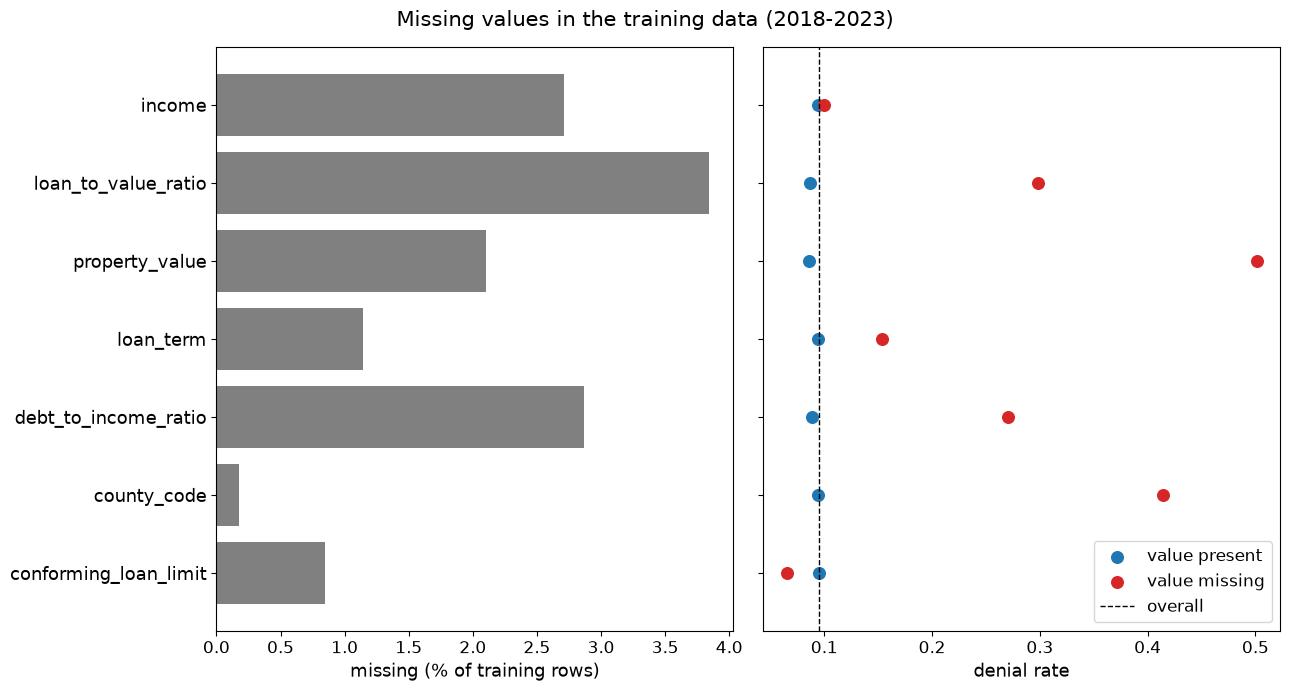

In [4]:
show = audit.iloc[::-1].reset_index(drop=True)
y_pos = np.arange(len(show))

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)

axes[0].barh(y_pos, show['missing_percent'], color='gray')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(show['feature'], fontsize=13)
axes[0].set_xlabel('missing (% of training rows)', fontsize=13)
axes[0].tick_params(axis='x', labelsize=12)

axes[1].scatter(show['denial_rate_not_missing'], y_pos, color='tab:blue', s=70, label='value present')
axes[1].scatter(show['denial_rate_missing'], y_pos, color='tab:red', s=70, label='value missing')
axes[1].axvline(train['denied'].mean(), color='black', linestyle='--', linewidth=1, label='overall')
axes[1].set_xlabel('denial rate', fontsize=13)
axes[1].tick_params(axis='x', labelsize=12)
axes[1].legend(fontsize=12, loc='lower right')

fig.suptitle('Missing values in the training data (2018-2023)', fontsize=15)
plt.tight_layout()
plt.savefig('../figures/fig_missing_values.png', dpi=300)
plt.show()

At most 3.84% of the rows are missing in one feature (loan_to_value_ratio). The denial rate is much higher when some values are missing: property_value 50.1% vs 8.6%, county_code 41.4% vs 9.4%, loan_to_value_ratio 29.8% vs 8.7%, debt_to_income_ratio 27.0% vs 8.9%. Each feature is compared on its own; other features are not held fixed.

## 3. How we handle them

### Categorical and ordinal features

`NA` is kept as its own category in all three features. The one-hot encoder needs `handle_unknown='ignore'`: new lenders and new codes appear every year (for example, aus-1 `7` first appears in 2021 and credit score type `11` in 2022).

debt_to_income_ratio is ordinal, and `NA` and `Exempt` have no place in the DTI order. `mv.dti_categories('first')` puts them before the DTI levels, `mv.dti_categories('last')` after them; the two can be compared with cross-validation. `NA` and `Exempt` stay two categories because their denial rates differ:

In [5]:
for code in ['NA', 'Exempt']:
    rows = train['debt_to_income_ratio'] == code
    print(code, rows.sum(), 'rows, denial rate', round(train.loc[rows, 'denied'].mean(), 3))

NA 2668 rows, denial rate 0.27
Exempt 848 rows, denial rate 0.072


### Continuous features

Missing in: income, loan_to_value_ratio, property_value, loan_term.

- LR: use `mv.continuous_imputer(random_state)`, then `StandardScaler`. LR cannot use NaN, and the rubric does not allow mean or median imputation.
- KNN: same as LR. KNN cannot compute distances with NaN.
- RF: same as LR. RF can use NaN, but with the same imputer LR, RF and KNN get the same data.
- XGBoost: no imputer. XGBoost uses NaN directly.
- LR, RF, KNN: use the same random state for the imputer and the model.

The imputer outputs 14 columns: the 10 continuous features and 4 indicator columns (`missingindicator_...`, 1 = was missing). The indicators are kept because missing values are linked to denial (Section 2).

In the pipeline, the imputer goes before the scaler:
```python
('cont', make_pipeline(mv.continuous_imputer(random_state), StandardScaler()), mv.continuous_ftrs)
```